In [27]:
import pandas as pd
import numpy as np
import tensorflow as tf

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import  StandardScaler , LabelEncoder
from sklearn.metrics import accuracy_score , confusion_matrix , classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense , Dropout
from tensorflow.keras.callbacks import EarlyStopping




In [28]:
data = pd.read_csv("Churn_Modelling.csv")
print("Dataset Shape : ",data.shape)
data.head()

Dataset Shape :  (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [29]:
#Distinguish the feature and target set 
# dropping irrelevent columns

x = data.drop(columns=['RowNumber','Surname','Exited','CustomerId'])
y=data['Exited']  # 'Exited' Column is the target

In [30]:
#Encoding categorical features 

le_geography = LabelEncoder()
x['Geography'] = le_geography.fit_transform(x['Geography'])

In [31]:
le_gender = LabelEncoder()
x['Gender'] = le_gender.fit_transform(x['Gender'])

In [32]:
# Step 3 : Split Data into Training and Testing Data

x_train , x_test , y_train , y_test = train_test_split(
    x , y , test_size=0.2 , random_state=42 
)

In [33]:
# Step 4 : Normalize the Dataset

scaler = StandardScaler()
x_train_scaled  = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [34]:
# Step 5 : Initialize and build the neural network model

model = Sequential()
model.add(Dense(64 , activation='relu' , input_shape=(x_train_scaled.shape[1],)))
model.add(Dropout(0.3)) # Adding dropout to prevent overfitting 
model.add(Dense(32,activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(1,activation='sigmoid')) # Output layer with sigmoid for binary classification

C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [35]:
# Compile model

model.compile(
    optimizer='adam' ,
    loss='binary_crossentropy' ,
    metrics=['accuracy']
)

In [36]:
# Early Stopping  Callback
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

In [37]:
history = model.fit(
    x_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping]
)

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6363 - loss: 2161.5381 - val_accuracy: 0.7987 - val_loss: 125.2503
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6820 - loss: 207.5096 - val_accuracy: 0.7987 - val_loss: 1.5926
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6963 - loss: 50.2077 - val_accuracy: 0.7987 - val_loss: 0.8486
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6875 - loss: 21.9154 - val_accuracy: 0.7987 - val_loss: 1.0172
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7214 - loss: 7.8336 - val_accuracy: 0.7000 - val_loss: 0.6363
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7433 - loss: 3.4794 - val_accuracy: 0.7987 - val_loss: 0.5321
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7653 - loss: 2.8689 - val_accuracy: 0.7987 - val_loss: 0.5390
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7683 - loss: 2.8920 - val_acc

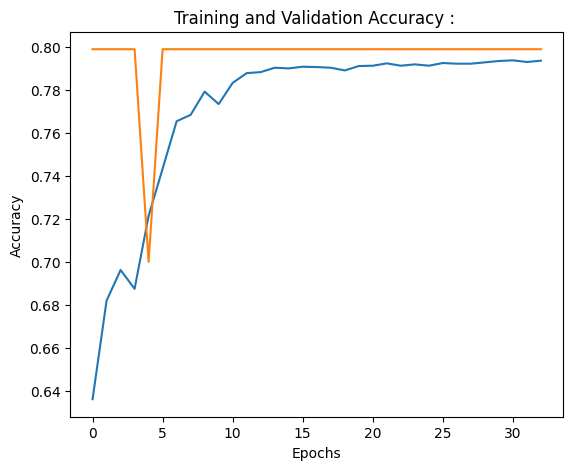

In [38]:
# Step 6 : Model Evaluation
# Plot training history

plt.figure(figsize=(14,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'] , label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label ='Validation Accuracy')
plt.title("Training and Validation Accuracy : ")
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()

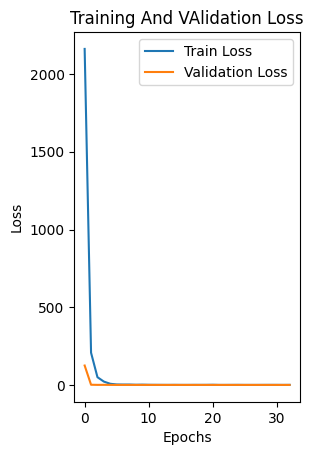

In [41]:
plt.subplot(1,2,2)
plt.plot(history.history['loss'] , label='Train Loss')
plt.plot(history.history['val_loss'] , label='Validation Loss')
plt.title('Training And VAlidation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [42]:
# Make Predication 
y_pred = (model.predict(x_test) > 0.5).astype("int32")


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [43]:
# Calculate Accuracy Score 

accuracy = accuracy_score(y_test,y_pred)
print("Accuracy : ",accuracy)

Accuracy :  0.8035


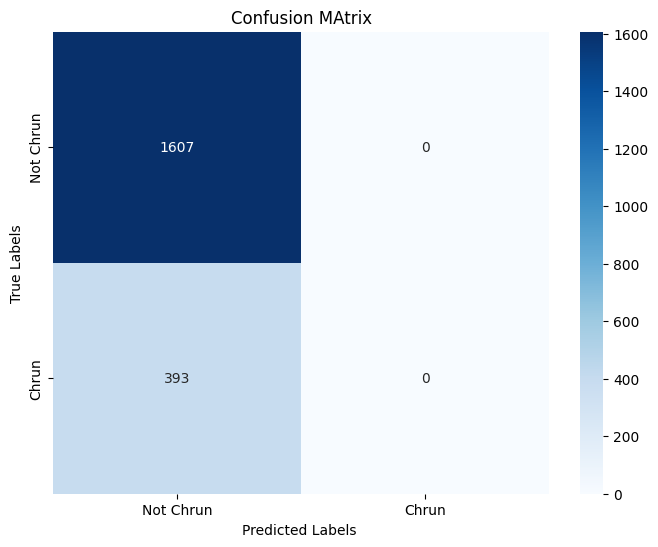

In [46]:
# Confusion Matrix 
cm = confusion_matrix(y_test,y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm , annot=True,fmt="d" , cmap="Blues" , xticklabels=['Not Chrun','Chrun'] , yticklabels=['Not Chrun','Chrun'])
plt.title("Confusion MAtrix")
plt.xlabel("Predicted Labels ")
plt.ylabel("True Labels")
plt.show()

In [47]:
# Classification Report 
print("Classification Report : \n",classification_report(y_test,y_pred))

Classification Report : 
               precision    recall  f1-score   support

           0       0.80      1.00      0.89      1607
           1       0.00      0.00      0.00       393

    accuracy                           0.80      2000
   macro avg       0.40      0.50      0.45      2000
weighted avg       0.65      0.80      0.72      2000



C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize

In [48]:
# Make Predication

y_pred = (model.predict(x_test)>0.5).astype("int32")

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [50]:
# convert predications back to the original DataFrame's Index
# First , create a Dataframe from y_test with matching indicies 
Y_test_df = y_test.reset_index(drop=True)

In [51]:
# Create a Dataframe fro prediction

prediction_df = pd.DataFrame(
    y_pred , columns=["Predicted"] , index= Y_test_df.index
)

In [52]:
# combine the prediction with the original test ser Dataframe (re_indexed)
results_df = x_test.copy()
results_df = pd.DataFrame(scaler.inverse_transform(results_df), columns=x.columns)
results_df['True Label'] = Y_test_df
results_df['Predicted Label'] = prediction_df

In [53]:
# Display the updated Dataframe with the true and predicted Labels
results_df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,True Label,Predicted Label
0,58082.313103,1.578489,1.043198,375.483213,13.648801,6.040244e+09,2.690712,0.703500,0.512750,2.403572e+09,0,0
1,60684.037881,0.750125,1.043198,491.184466,7.885517,7.610214e+04,2.690712,1.160214,1.012587,8.419154e+09,0,0
2,58564.113988,2.406854,0.545250,501.702762,16.530443,7.610214e+04,2.690712,1.160214,0.512750,3.368273e+09,0,0
3,49409.897175,1.578489,1.043198,659.477198,28.057010,7.441971e+09,2.690712,1.160214,1.012587,9.816801e+09,0,0
4,54613.346732,2.406854,0.545250,322.891735,25.175368,7.806963e+09,2.111044,1.160214,1.012587,6.595371e+09,0,0
